# Statistics & Probability Hands-on Analysis

This project explores foundational statistical and probabilistic techniques in Python using two real-world datasets:
1. **UN Country Profile Variables Dataset**: Used for exploratory data analysis (EDA), descriptive statistics (central tendency, dispersion, quartiles), outlier detection via Tukey's IQR rule, correlation analysis, and categorical label encoding.
2. **Restaurant Tips Dataset (Seaborn)**: Used for calculating marginal probabilities and conditional probabilities using event-based formulations.


## Part 1: Exploratory Data Analysis & Descriptive Statistics (Country Profile)

### 1.1 Import Required Libraries


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Set plot styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.autolayout'] = True


### 1.2 Load Dataset
The UN Country Profile dataset is loaded from the `data/` directory (with automatic fallback to root).


In [2]:
# Locate and load the dataset
data_path = 'data/country_profile_variables.csv' if os.path.exists('data/country_profile_variables.csv') else 'country_profile_variables.csv'
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")
print(f"Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")


Dataset loaded successfully from: data/country_profile_variables.csv
Dimensions: 229 rows, 50 columns


### 1.3 Initial Data Inspection
Inspecting the first 5 rows, last 5 rows, and metadata summary.


In [3]:
# Display first 5 rows
df.head(5)


,country,Region,Surface area (km2),Population in thousands (2017),"Population density (per km2, 2017)","Sex ratio (m per 100 f, 2017)",GDP: Gross domestic product (million current US$),"GDP growth rate (annual %, const. 2005 prices)",GDP per capita (current US$),Economy: Agriculture (% of GVA),...,Mobile-cellular subscriptions (per 100 inhabitants).1,Individuals using the Internet (per 100 inhabitants),Threatened species (number),Forested area (% of land area),CO2 emission estimates (million tons/tons per capita),"Energy production, primary (Petajoules)",Energy supply per capita (Gigajoules),"Pop. using improved drinking water (urban/rural, %)","Pop. using improved sanitation facilities (urban/rural, %)",Net Official Development Assist. received (% of GNI)
0,Afghanistan,SouthernAsia,652864,35530,54.4,106.3,20270,-2.4,623.2,23.3,...,8.3,42,2.1,9.8/0.3,63,5,78.2/47.0,45.1/27.0,21.43,-99
1,Albania,SouthernEurope,28748,2930,106.9,101.9,11541,2.6,3984.2,22.4,...,63.3,130,28.2,5.7/2.0,84,36,94.9/95.2,95.5/90.2,2.96,-99
2,Algeria,NorthernAfrica,2381741,41318,17.3,102.0,164779,3.8,4154.1,12.2,...,38.2,135,0.8,145.4/3.7,5900,55,84.3/81.8,89.8/82.2,0.05,-99
3,American Samoa,Polynesia,199,56,278.2,103.6,-99,-99,-99.0,-99,...,-99,92,87.9,-99,-99,-99,100.0/100.0,62.5/62.5,-99,-99
4,Andorra,SouthernEurope,468,77,163.8,102.3,2812,0.8,39896.4,0.5,...,96.9,13,34.0,0.5/6.4,1,119,100.0/100.0,100.0/100.0,-99,-99


In [4]:
# Display last 5 rows
df.tail(5)


,country,Region,Surface area (km2),Population in thousands (2017),"Population density (per km2, 2017)","Sex ratio (m per 100 f, 2017)",GDP: Gross domestic product (million current US$),"GDP growth rate (annual %, const. 2005 prices)",GDP per capita (current US$),Economy: Agriculture (% of GVA),...,Mobile-cellular subscriptions (per 100 inhabitants).1,Individuals using the Internet (per 100 inhabitants),Threatened species (number),Forested area (% of land area),CO2 emission estimates (million tons/tons per capita),"Energy production, primary (Petajoules)",Energy supply per capita (Gigajoules),"Pop. using improved drinking water (urban/rural, %)","Pop. using improved sanitation facilities (urban/rural, %)",Net Official Development Assist. received (% of GNI)
224,Wallis and Futuna Islands,Polynesia,142,12,84.1,93.4,-99,-99,-99.0,-99,...,9.0,89,41.6,~0.0/1.6,-99,26,-99,-99,-99,-99
225,Western Sahara,NorthernAfrica,266000,553,2.1,110.1,-99,-99,-99.0,-99,...,-99,49,2.7,-99,-99,-99,-99,-99,-99,-99
226,Yemen,WesternAsia,527968,28250,53.5,102.1,29688,-28.1,1106.4,14.7,...,25.1,298,1.0,22.7/0.9,668,12,72.0/46.5,92.5/34.1,2.99,-99
227,Zambia,EasternAfrica,752612,17094,23.0,98.5,21255,2.9,1311.1,8.2,...,21.0,88,65.6,4.5/0.3,374,26,85.6/51.3,55.6/35.7,3.96,-99
228,Zimbabwe,EasternAfrica,390757,16530,42.7,95.0,13893,1.1,890.4,13.0,...,16.4,89,37.2,12.0/0.8,482,30,97.0/67.3,49.3/30.8,6.00,-99


In [5]:
# Dataset schema and column information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 229 entries, 0 to 228
Data columns (total 50 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   country                                                     229 non-null    str    
 1   Region                                                      229 non-null    str    
 2   Surface area (km2)                                          229 non-null    str    
 3   Population in thousands (2017)                              229 non-null    int64  
 4   Population density (per km2, 2017)                          229 non-null    float64
 5   Sex ratio (m per 100 f, 2017)                               229 non-null    float64
 6   GDP: Gross domestic product (million current US$)           229 non-null    int64  
 7   GDP growth rate (annual %, const. 2005 prices)              229 non-null    str    
 8   GDP per cap

### 1.4 Reproducible Random Sampling
We draw a random sample of 30 countries using a fixed `random_state` (seed) to ensure deterministic, reproducible results across runs.


In [6]:
# Sample 30 records reproducibly
df_sample = df.sample(30, random_state=42)
df_sample[['country', 'Region', 'Population in thousands (2017)']].head()


,country,Region,Population in thousands (2017)
216,United Republic of Tanzania,EasternAfrica,57310
66,Estonia,NorthernEurope,1310
9,Armenia,WesternAsia,2930
192,State of Palestine,WesternAsia,4921
15,Bahrain,WesternAsia,1493


### 1.5 Measures of Central Tendency

Measures of central tendency summarize a dataset by identifying its central point:
- **Mean**: The arithmetic average ($\frac{\sum x}{n}$). Sensitive to extreme values (outliers).
- **Median**: The middle value of an ordered dataset ($50^{\text{th}}$ percentile). Robust to outliers and skewness.
- **Mode**: The most frequently occurring value in a categorical or discrete feature.


In [7]:
pop_col = 'Population in thousands (2017)'

# Mean calculation manually and via pandas
sum_pop = df[pop_col].sum()
count_pop = len(df[pop_col])
mean_pop_manual = sum_pop / count_pop
mean_pop = df[pop_col].mean()

# Median calculation
median_pop = df[pop_col].median()

# Mode calculation for Region
region_mode = df['Region'].mode()[0]
region_mode_freq = (df['Region'] == region_mode).sum()

print(f"Sum of Population: {sum_pop:,} thousand")
print(f"Total Countries:   {count_pop}")
print(f"Manual Mean:      {mean_pop_manual:,.2f} thousand")
print(f"Pandas Mean:      {mean_pop:,.2f} thousand")
print(f"Median:           {median_pop:,.2f} thousand")
print(f"Mode Region:      {region_mode} (appears {region_mode_freq} times out of {count_pop})")
print(f"\nObservation: Mean ({mean_pop:,.2f}) is significantly higher than Median ({median_pop:,.2f}), indicating strong right-skewness caused by heavily populated nations.")


Sum of Population: 7,501,306 thousand
Total Countries:   229
Manual Mean:      32,756.79 thousand
Pandas Mean:      32,756.79 thousand
Median:           5,448.00 thousand
Mode Region:      Caribbean (appears 25 times out of 229)

Observation: Mean (32,756.79) is significantly higher than Median (5,448.00), indicating strong right-skewness caused by heavily populated nations.


### 1.6 Measures of Dispersion & Quartiles

Measures of dispersion describe the spread and variability of the data:
- **Range**: Difference between Maximum and Minimum ($\text{Range} = \max - \min$).
- **Quantiles/Percentiles**: Split ordered data into portions:
  - $Q_1$ ($25^{\text{th}}$ percentile): Lower quartile
  - $Q_2$ ($50^{\text{th}}$ percentile): Median
  - $Q_3$ ($75^{\text{th}}$ percentile): Upper quartile
- **Interquartile Range (IQR)**: Middle 50% spread ($IQR = Q_3 - Q_1$).


In [8]:
# Range calculation
min_pop = df[pop_col].min()
max_pop = df[pop_col].max()
pop_range = max_pop - min_pop

# Quartiles
q1 = df[pop_col].quantile(0.25)
q2 = df[pop_col].quantile(0.50)
q3 = df[pop_col].quantile(0.75)
iqr = q3 - q1

print(f"Minimum Population:   {min_pop:,} thousand")
print(f"Maximum Population:   {max_pop:,} thousand")
print(f"Range:                {pop_range:,} thousand")
print(f"Q1 (25th percentile): {q1:,} thousand")
print(f"Q2 (50th percentile): {q2:,} thousand")
print(f"Q3 (75th percentile): {q3:,} thousand")
print(f"IQR (Q3 - Q1):        {iqr:,} thousand")


Minimum Population:   1 thousand
Maximum Population:   1,409,517 thousand
Range:                1,409,516 thousand
Q1 (25th percentile): 431.0 thousand
Q2 (50th percentile): 5,448.0 thousand
Q3 (75th percentile): 19,193.0 thousand
IQR (Q3 - Q1):        18,762.0 thousand


### 1.7 Visualizing Spread & Outliers: Box Plot
A box plot visually depicts the five-number summary: Minimum, Q1, Median, Q3, and Maximum, with outliers shown as individual points beyond Tukey's fences.


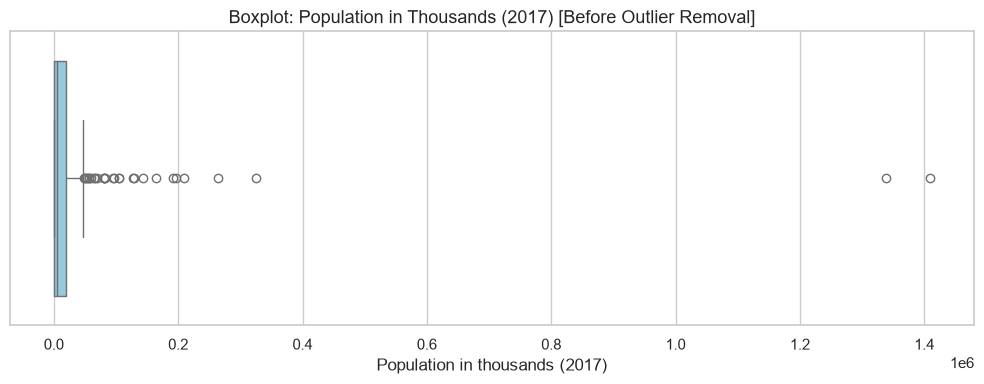

In [9]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[pop_col], color='skyblue')
plt.title("Boxplot: Population in Thousands (2017) [Before Outlier Removal]", fontsize=13)
plt.xlabel("Population in thousands (2017)")
plt.show()


### 1.8 Outlier Detection & Filtering using Tukey's Fences (IQR Method)

Using John Tukey's standard convention, data points falling outside the fences are identified as statistical outliers:
$$\text{Lower Bound (LB)} = Q_1 - 1.5 \times IQR$$
$$\text{Upper Bound (UB)} = Q_3 + 1.5 \times IQR$$


In [10]:
# Calculate Tukey's Fences for Population
lb = q1 - 1.5 * iqr
ub = q3 + 1.5 * iqr

print(f"Lower Bound: {lb:,.2f}")
print(f"Upper Bound: {ub:,.2f}")

# Filter population outliers
outliers = df[(df[pop_col] < lb) | (df[pop_col] > ub)]
df_filtered = df[(df[pop_col] >= lb) & (df[pop_col] <= ub)].copy()

print(f"Total records before filtering:          {len(df)}")
print(f"Number of population outliers detected:  {len(outliers)}")
print(f"Records remaining after filtering:       {len(df_filtered)}")


Lower Bound: -27,712.00
Upper Bound: 47,336.00
Total records before filtering:          229
Number of population outliers detected:  29
Records remaining after filtering:       200


#### Generalized Reusable Function for Outlier Removal
We encapsulate this logic into a reusable function for numerical columns with correct indentation and copy protection.


In [11]:
def remove_outliers_iqr(df_in, columns=None, factor=1.5):
    '''
    Removes outliers from specified numerical columns using Tukey's IQR rule.
    
    Parameters:
        df_in (pd.DataFrame): Input dataframe
        columns (list): Numerical columns to filter. If None, uses all numeric columns.
        factor (float): IQR multiplier (default 1.5)
        
    Returns:
        pd.DataFrame: Cleaned dataframe without outliers
    '''
    df_clean = df_in.copy()
    if columns is None:
        columns = df_clean.select_dtypes(include=[np.number]).columns.tolist()
        
    for col in columns:
        q1_c = df_clean[col].quantile(0.25)
        q3_c = df_clean[col].quantile(0.75)
        iqr_c = q3_c - q1_c
        lower = q1_c - factor * iqr_c
        upper = q3_c + factor * iqr_c
        df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]
        
    return df_clean

# Example verification on population column
cleaned_test = remove_outliers_iqr(df, columns=[pop_col])
print(f"Shape after generalized function call: {cleaned_test.shape}")


Shape after generalized function call: (200, 50)


### 1.9 Correlation Analysis & Heatmap
Correlation measures the strength and direction of linear relationships between numerical variables, ranging from $-1$ (perfect negative correlation) to $+1$ (perfect positive correlation).


Numeric feature matrix shape: (200, 16)


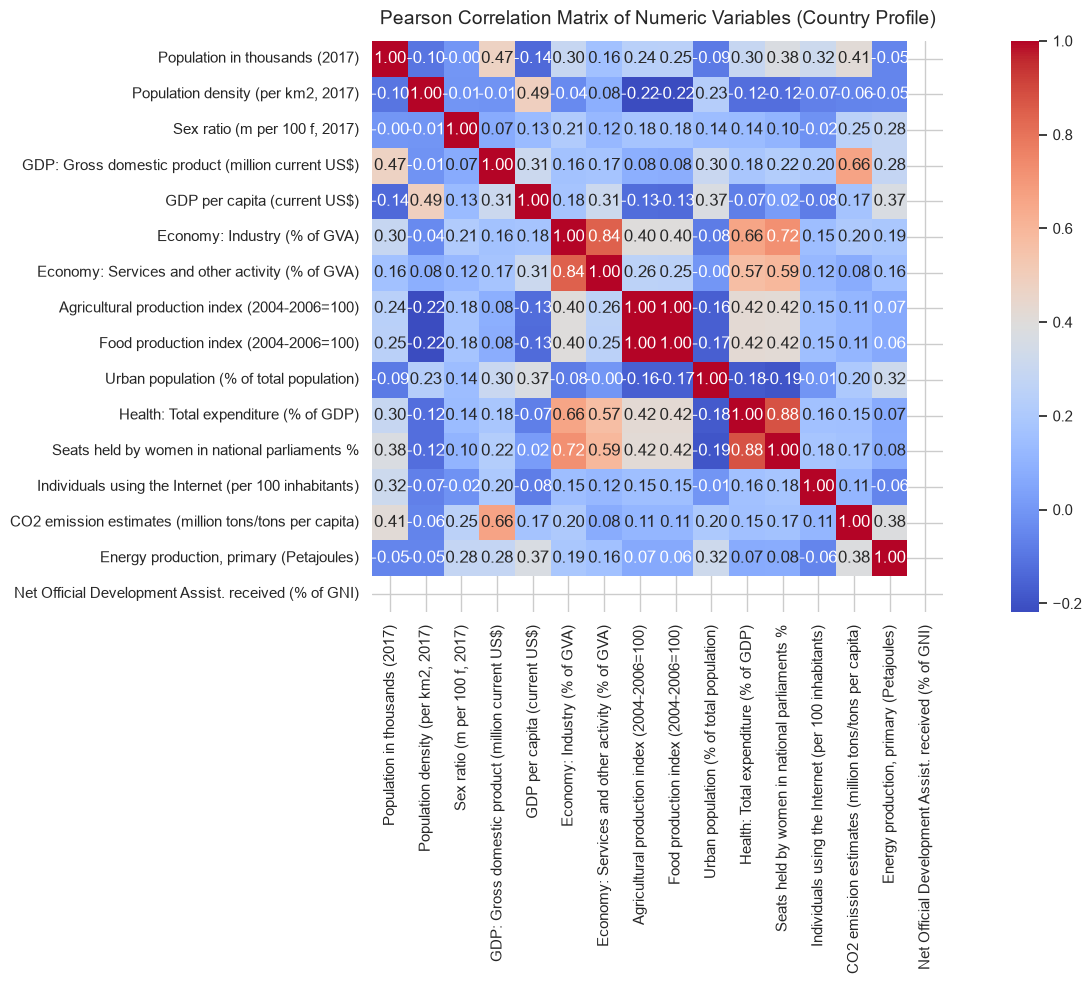

In [12]:
# Select numeric columns from the filtered dataset
num_df = df_filtered.select_dtypes(include=[np.number])
print(f"Numeric feature matrix shape: {num_df.shape}")

# Compute Pearson correlation matrix
corr_mat = num_df.corr()

# Visualize with Seaborn Heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title("Pearson Correlation Matrix of Numeric Variables (Country Profile)", fontsize=14, pad=12)
plt.show()


### 1.10 Categorical Feature Encoding (Label Encoding)
Machine learning models and statistical estimators require numerical input. `LabelEncoder` maps categorical labels to discrete integers $[0, n_{\text{classes}}-1]$.


In [13]:
# Inspect unique values in 'Region'
print(f"Number of unique regions: {df_filtered['Region'].nunique()}")
print(f"Top 5 regions by frequency:\n{df_filtered['Region'].value_counts().head(5)}\n")

# Apply Label Encoding
le = LabelEncoder()
df_filtered['Region_Encoded'] = le.fit_transform(df_filtered['Region'])

# Display mapping between original classes and assigned integers
mapping = {cls: idx for idx, cls in enumerate(le.classes_)}
print("LabelEncoder Mapping (.classes_ -> Encoded Integer):")
for cls, idx in list(mapping.items())[:8]:
    print(f"  {cls:<25} -> {idx}")


Number of unique regions: 22
Top 5 regions by frequency:
Region
Caribbean         25
WesternAsia       17
EasternAfrica     16
SouthernEurope    15
WesternAfrica     15
Name: count, dtype: int64

LabelEncoder Mapping (.classes_ -> Encoded Integer):
  Caribbean                 -> 0
  CentralAmerica            -> 1
  CentralAsia               -> 2
  EasternAfrica             -> 3
  EasternAsia               -> 4
  EasternEurope             -> 5
  Melanesia                 -> 6
  Micronesia                -> 7


In [14]:
def encode_categorical_columns(df_in):
    '''
    Label-encodes all categorical (object) columns and returns the encoded dataframe
    along with a dictionary of fitted LabelEncoders for inverse transformation.
    '''
    df_encoded = df_in.copy()
    encoders = {}
    for col in df_encoded.select_dtypes(include=['object']).columns:
        enc = LabelEncoder()
        df_encoded[col] = enc.fit_transform(df_encoded[col].astype(str))
        encoders[col] = enc
    return df_encoded, encoders

df_all_encoded, fitted_encoders = encode_categorical_columns(df_filtered)
print(f"All categorical columns encoded. New shape: {df_all_encoded.shape}")
df_all_encoded[['country', 'Region', pop_col]].head()


All categorical columns encoded. New shape: (200, 51)


C:\Users\Sonal Thorat\AppData\Local\Temp\ipykernel_15564\2126277474.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_encoded.select_dtypes(include=['object']).columns:


,country,Region,Population in thousands (2017)
0,0,17,35530
1,1,18,2930
2,2,9,41318
3,3,13,56
4,4,18,77


---
## Part 2: Probability Theory & Conditional Probability (Tips Dataset)

Using Seaborn's standard restaurant dining dataset (`tips`), we examine:
- **Marginal Probability**: $P(A) = \frac{\text{Outcomes favoring } A}{\text{Total outcomes}}$
- **Conditional Probability**: $P(A \mid B) = \frac{P(A \cap B)}{P(B)} = \frac{n(A \cap B)}{n(B)}$
- **Compound / Union Probability**: $P(A \cup B \mid C)$


In [15]:
# Load the Tips dataset
tips = sns.load_dataset('tips')
print(f"Tips dataset shape: {tips.shape}")
tips.head()


Tips dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### 2.1 Marginal Probability: $P(\text{Day} = \text{Sunday})$
What is the probability of a dining transaction occurring on Sunday?
$$P(\text{Day} = \text{Sunday}) = \frac{\text{Number of Sunday records}}{\text{Total records}}$$


In [16]:
fav_sun = (tips['day'] == 'Sun').sum()
total_records = len(tips)
prob_sun = fav_sun / total_records

print(f"Favorable outcomes (Sunday): {fav_sun}")
print(f"Total outcomes:              {total_records}")
print(f"P(Day = Sunday):             {prob_sun:.4f} ({prob_sun * 100:.2f}%)")


Favorable outcomes (Sunday): 76
Total outcomes:              244
P(Day = Sunday):             0.3115 (31.15%)


### 2.2 Conditional Probability: $P(\text{Day} = \text{Sunday} \mid \text{Time} = \text{Dinner})$
Given that the meal was Dinner, what is the probability that the day was Sunday?
$$P(\text{Day} = \text{Sun} \mid \text{Time} = \text{Dinner}) = \frac{n(\text{Day} = \text{Sun} \cap \text{Time} = \text{Dinner})}{n(\text{Time} = \text{Dinner})}$$


In [17]:
# Condition: Time is Dinner
dinner_records = tips[tips['time'] == 'Dinner']
total_dinner = len(dinner_records)

# Intersection: Time is Dinner AND Day is Sunday
fav_dinner_sun = (dinner_records['day'] == 'Sun').sum()

prob_sun_given_dinner = fav_dinner_sun / total_dinner

print(f"Favorable outcomes (Dinner & Sunday): {fav_dinner_sun}")
print(f"Condition total outcomes (Dinner):    {total_dinner}")
print(f"P(Day = Sun | Time = Dinner):        {prob_sun_given_dinner:.4f} ({prob_sun_given_dinner * 100:.2f}%)")


Favorable outcomes (Dinner & Sunday): 76
Condition total outcomes (Dinner):    176
P(Day = Sun | Time = Dinner):        0.4318 (43.18%)


### 2.3 Compound Conditional Probability: $P(\text{Day} \in \{\text{Friday}, \text{Saturday}\} \mid \text{Time} = \text{Dinner})$
Given that the meal was Dinner, what is the probability that the day was either Friday or Saturday?
$$P(\text{Day} \in \{\text{Fri}, \text{Sat}\} \mid \text{Time} = \text{Dinner}) = \frac{n(\text{Day} \in \{\text{Fri}, \text{Sat}\} \cap \text{Time} = \text{Dinner})}{n(\text{Time} = \text{Dinner})}$$


In [18]:
fav_dinner_fri_sat = dinner_records['day'].isin(['Fri', 'Sat']).sum()
prob_fri_sat_given_dinner = fav_dinner_fri_sat / total_dinner

print(f"Favorable outcomes (Dinner on Fri or Sat): {fav_dinner_fri_sat}")
print(f"Condition total outcomes (Dinner):         {total_dinner}")
print(f"P(Day in [Fri, Sat] | Time = Dinner):      {prob_fri_sat_given_dinner:.4f} ({prob_fri_sat_given_dinner * 100:.2f}%)")


Favorable outcomes (Dinner on Fri or Sat): 99
Condition total outcomes (Dinner):         176
P(Day in [Fri, Sat] | Time = Dinner):      0.5625 (56.25%)


### 2.4 Summary of Probability Calculations
A structured comparison of the calculated marginal and conditional probabilities.


In [19]:
# Summary Table
prob_summary = pd.DataFrame([
    {
        "Event": "P(Day = Sunday)",
        "Favorable Count": fav_sun,
        "Sample Space": total_records,
        "Probability": f"{prob_sun:.4f}",
        "Percentage": f"{prob_sun * 100:.2f}%"
    },
    {
        "Event": "P(Day = Sunday | Time = Dinner)",
        "Favorable Count": fav_dinner_sun,
        "Sample Space": total_dinner,
        "Probability": f"{prob_sun_given_dinner:.4f}",
        "Percentage": f"{prob_sun_given_dinner * 100:.2f}%"
    },
    {
        "Event": "P(Day in [Fri, Sat] | Time = Dinner)",
        "Favorable Count": fav_dinner_fri_sat,
        "Sample Space": total_dinner,
        "Probability": f"{prob_fri_sat_given_dinner:.4f}",
        "Percentage": f"{prob_fri_sat_given_dinner * 100:.2f}%"
    }
])

prob_summary


,Event,Favorable Count,Sample Space,Probability,Percentage
0,P(Day = Sunday),76,244,0.3115,31.15%
1,P(Day = Sunday | Time = Dinner),76,176,0.4318,43.18%
2,"P(Day in [Fri, Sat] | Time = Dinner)",99,176,0.5625,56.25%
